# Un factor de roca que no usa nada del sitio objetivo, y cuánto del puntaje clásico era prestado

**Pregunta:** ¿Se puede predecir el factor de roca desde el módulo de los otros sitios, y qué cuesta?

**Nivel 4: Más allá del estado del arte** · Requiere: 02-classical-prediction/02-the-rock-factor, 02-classical-prediction/03-the-published-hold-out-tables · Tiempo de lectura: unos 35 minutos

## Objetivos

El predictor clásico de los notebooks anteriores lee un factor de roca que se recuperó de las predicciones publicadas para el mismo sitio sobre el que se puntúa. Dejado fuera por sitio, eso es conocimiento del sitio dejado fuera, que a un predictor aprendido nunca se le da. Este notebook mide cuánto del puntaje clásico compra ese conocimiento, reemplazando la constante del sitio por un factor predicho desde el módulo de Young de la roca usando solo los otros sitios (afirmación BS-4).

Al terminar, usted habrá:

- tabulado los nueve factores recuperados contra los módulos de los sitios, ajustado la relación log-lineal entre ellos y leído su pendiente y su correlación;
- predicho el factor de cada sitio desde los otros nueve, y comparado con el factor recuperado del artículo;
- puntuado el predictor de factor por sitio, el de transferencia y una constante bajo dejar-un-sitio-fuera, con intervalos que remuestrean sitios;
- leído, sitio a sitio, dónde ayuda reemplazar el factor y dónde cuesta.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, fija el estilo de los gráficos y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones fijadas, estilo de gráficos y un ayudante de tablas
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros y sus módulos de roca | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los factores de roca por sitio recuperados de las predicciones impresas | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la columna de 2012) | hechos numéricos reutilizados con cita | `bf.derive_site_rock_factors` y `bf.SITE_ROCK_FACTOR` dentro del paquete |

No se lee ningún archivo de `data/`: las ejecuciones dejar-un-sitio-fuera se corren aquí, con el motor.

## Método

El predictor de transferencia ajusta una recta en logaritmos por los sitios,

```
ln A = a + b * ln E
```

con un punto por sitio (el factor recuperado del sitio contra su módulo medio), así que una cantera de 22 tiros y una mina de seis pesan lo mismo. El factor de un tiro es entonces `exp(a + b ln E)` desde su propio módulo, que un ingeniero tiene antes del primer tiro en una mina nueva. La relación es una calibración de este motor, no una ecuación publicada. Bajo dejar-un-sitio-fuera, la recta se reajusta sin el sitio dejado fuera en cada pliegue, así que el sitio dejado fuera no aporta nada a su propio factor. El puntaje de un predictor es la varianza explicada respecto de la línea de identidad; su intervalo viene de un bootstrap que remuestrea sitios, no tiros, porque las filas de una campaña no son observaciones independientes (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

### Paso 1: los factores y los módulos de los nueve sitios

La celda pide al motor el factor recuperado de cada sitio, `derive_site_rock_factors("kuzram_2012")`, y calcula el módulo medio de la roca de cada sitio desde el corpus. La tabla ordena los sitios por módulo, de modo que cualquier relación entre las dos columnas se lea hacia abajo de la página.

In [2]:
# El factor recuperado y el módulo medio de cada sitio, desde la derivación del motor
train = bf.load_training_corpus()
derived = bf.derive_site_rock_factors("kuzram_2012")
sites = sorted(derived)
modulus = {site: float(np.mean([b.E_GPa for b in train if b.site == site])) for site in sites}
rows = []
for site in sorted(sites, key=modulus.get):
    rows.append((site, f"{modulus[site]:.2f}", f"{derived[site][0]:.2f}", derived[site][1]))
header = ["sitio", "módulo medio E (GPa)", "factor de roca recuperado A",
          "tiros usados"]
show_table(header, rows)

| sitio | módulo medio E (GPa) | factor de roca recuperado A | tiros usados |
|:---|---:|---:|---:|
| Dongri-Buzurg | 9.57 | 3.68 | 1 |
| Soma | 13.25 | 6.24 | 1 |
| Ozmert | 15.00 | 6.44 | 2 |
| Akdaglar | 16.90 | 6.72 | 2 |
| Mrica | 32.00 | 6.32 | 1 |
| Reocin | 45.00 | 12.14 | 1 |
| Reocin-UG | 45.00 | 11.19 | 1 |
| Murgul | 50.00 | 9.23 | 2 |
| Enusa | 60.00 | 10.97 | 1 |

Léase hacia abajo de la tabla: el factor sube con el módulo, de 3.68 con 9.57 GPa (Dongri-Buzurg) a 10.97 con 60 GPa (Enusa), pero no suavemente. Mrica, con 32 GPa, tiene un factor de 6.32, bajo el 6.72 de Akdaglar con 16.9 GPa, y Reocin y Reocin-UG comparten un módulo de 45 GPa con factores de 12.14 y 11.19. Así que la relación es una tendencia con dispersión, que una recta solo puede captar de forma aproximada. La tabla fija los nueve pares que ajusta la celda siguiente; no dice nada de su vínculo causal.

In [3]:
# Ajustar la recta log-lineal por los nueve sitios y medir qué tan estrecha es la relación
transfer = bf.KuznetsovTransfer().fit(train)
log_e = np.log([modulus[site] for site in transfer.fit_sites])
log_a = np.log([derived[site][0] for site in transfer.fit_sites])
correlation = np.corrcoef(log_e, log_a)[0, 1]
rows = [("intercepto a", f"{transfer.intercept:.4f}"), ("pendiente b", f"{transfer.slope:.4f}"),
        ("sitios en el ajuste", len(transfer.fit_sites)), ("correlación de ln A con ln E", f"{correlation:.3f}")]
show_table(["magnitud", "valor"], rows)

| magnitud | valor |
|:---|---:|
| intercepto a | 0.3841 |
| pendiente b | 0.5029 |
| sitios en el ajuste | 9 |
| correlación de ln A con ln E | 0.891 |

La recta tiene un intercepto de 0.3841 y una pendiente de 0.5029 sobre los nueve sitios, así que el factor crece aproximadamente con la raíz cuadrada del módulo, y la correlación de los logaritmos es 0.891. Una correlación fuerte sobre nueve puntos es alentadora y aun así una evidencia débil: nueve puntos restringen una recta, no una ley. La celda siguiente dibuja los nueve puntos y la recta.

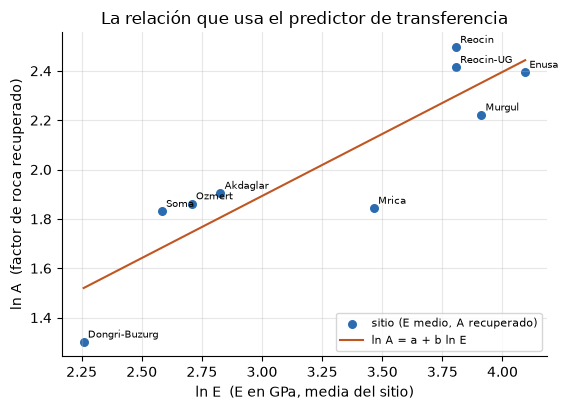

In [4]:
# ln A contra ln E para los nueve sitios, con la recta ajustada
fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.scatter(log_e, log_a, s=30, color="#2b6cb0", label="sitio (E medio, A recuperado)")
for site, x, y in zip(transfer.fit_sites, log_e, log_a):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
grid = np.linspace(log_e.min(), log_e.max(), 20)
ax.plot(grid, transfer.intercept + transfer.slope * grid, color="#c05621", label="ln A = a + b ln E")
ax.set_xlabel("ln E  (E en GPa, media del sitio)")
ax.set_ylabel("ln A  (factor de roca recuperado)")
ax.set_title("La relación que usa el predictor de transferencia")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

Los nueve sitios quedan cerca de la recta naranja, con las mayores desviaciones en Mrica y en Dongri-Buzurg, ambos bajo ella, lo que significa que la recta sobrestima sus factores, mientras Reocin y Reocin-UG quedan sobre ella con la misma abscisa. La figura muestra que un solo módulo lleva una parte real de la información sobre el factor de roca. No muestra que la recta se sostendría en un décimo sitio, pues cada punto aquí también contribuyó a ajustarla; eso es lo que ponen a prueba las ejecuciones dejar-un-sitio-fuera de los pasos siguientes.

## Estado del arte

- Los dos artículos fuente (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3) declaran que el factor de roca se estimó para cada tiro y no imprimen ningún valor. Los factores recuperados de sus predicciones se comportan como una constante por sitio (el notebook anterior: una dispersión de pocos por ciento dentro de un sitio).
- Toda evaluación de la ecuación clásica que use esos factores en el mismo sitio le da por tanto a la ecuación un número ajustado al sitio, y la base de investigación del SDD anota que los estudios publicados de predictores aprendidos no dejan fuera una mina completa. Un puntaje con sitio dejado fuera de ese predictor no puede separar la habilidad de la ecuación del origen del factor.
- Remuestrear la unidad correcta importa: una validación cruzada que ignora la dependencia en los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Más allá del estado del arte

**Afirmación BS-4, un factor de roca que no usa nada del sitio objetivo.** El predictor de transferencia reemplaza la constante del sitio por un factor predicho desde el módulo de los otros sitios. Su premisa es comprobable: bajo dejar-un-sitio-fuera, ¿en qué se convierte el puntaje clásico cuando se quita el factor propio del sitio dejado fuera, y cuánto se mueve la respuesta? Los tres pasos siguientes dejan fuera cada campaña por turno, comparan el factor predicho con el recuperado, puntúan tres predictores con intervalos que remuestrean sitios, y leen el costo sitio a sitio.

### Paso 2: dejar un sitio fuera y predecir su factor desde los otros

Para cada una de las diez campañas la celda deja fuera la campaña completa, reajusta la recta de transferencia con las otras nueve, predice la campaña dejada fuera con tres predictores (el predictor clásico de factor por sitio, el de transferencia y el modelo nulo que predice la media de las otras campañas) y registra el factor que le dio la recta de transferencia. Miami no tiene escala, así que ambos predictores clásicos se abstienen allí; su factor se predice igualmente, y no tiene con qué compararse. La tabla pone cada factor predicho junto al recuperado.

In [5]:
# Dejar fuera cada campaña por turno, reajustar con las otras nueve y guardar lo que dice de ella cada predictor clásico
tested, predictions, predicted_factor = [], {"kuznetsov": [], "kuznetsov-transfer": [], "null": []}, {}
for split in bf.leave_one_site_out(train):
    site = split.detail["held_out_site"]
    refit = bf.KuznetsovTransfer().fit(split.train)
    predictions["kuznetsov"] += bf.Kuznetsov().fit(split.train).predict(split.test)
    predictions["kuznetsov-transfer"] += refit.predict(split.test)
    predictions["null"] += bf.NullModel().fit(split.train).predict(split.test)
    tested += list(split.test)
    predicted_factor[site] = refit.rock_factor_for(float(np.mean([b.E_GPa for b in split.test])))
rows = []
for site, factor in predicted_factor.items():
    recovered = bf.SITE_ROCK_FACTOR.get(site)
    error = f"{factor / recovered - 1:+.1%}" if recovered else "-"
    rows.append((site, f"{recovered:.2f}" if recovered else "-", f"{factor:.2f}", error))
header = ["sitio dejado fuera", "A recuperado", "A predicho desde los otros sitios",
          "error relativo"]
show_table(header, rows)

| sitio dejado fuera | A recuperado | A predicho desde los otros sitios | error relativo |
|:---|---:|---:|---:|
| Akdaglar | 6.72 | 5.97 | -11.2% |
| Dongri-Buzurg | 3.68 | 5.25 | +42.6% |
| Enusa | 10.97 | 11.74 | +7.0% |
| Miami | - | 4.67 | - |
| Mrica | 6.32 | 8.72 | +38.0% |
| Murgul | 9.23 | 10.89 | +18.0% |
| Ozmert | 6.44 | 5.57 | -13.5% |
| Reocin | 12.14 | 9.51 | -21.6% |
| Reocin-UG | 11.19 | 9.69 | -13.4% |
| Soma | 6.24 | 5.14 | -17.6% |

Predicho solo desde los otros sitios, el factor cae a 7.0 por ciento del recuperado en Enusa y a 11.2 por ciento en Akdaglar, y falla en 42.6 por ciento en Dongri-Buzurg, el sitio de menor módulo, hacia donde la recta debe extrapolar, y en 38.0 por ciento en Mrica. Los errores tienen ambos signos: la recta sobrestima Dongri-Buzurg, Mrica, Murgul y Enusa y subestima los otros cinco. Miami recibe 4.67, un valor sin nada con qué comprobarlo. La tabla lista los errores de cada pliegue; la celda siguiente los dibuja.

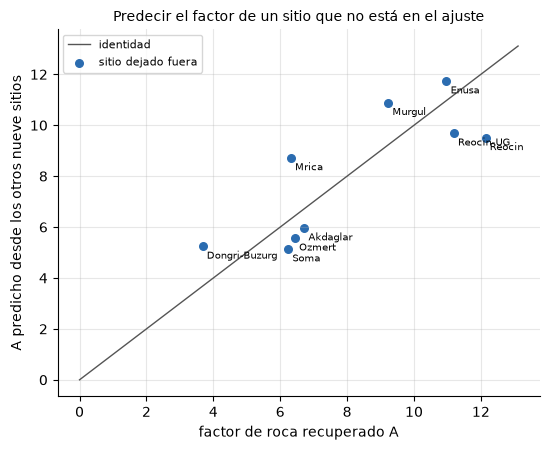

error relativo absoluto mediano: 17.6% | mayor: 42.6%


In [6]:
# Factor predicho desde los otros sitios contra el recuperado del artículo, un punto por sitio dejado fuera
known = [site for site in predicted_factor if site in bf.SITE_ROCK_FACTOR]
recovered = np.array([bf.SITE_ROCK_FACTOR[s] for s in known])
predicted = np.array([predicted_factor[s] for s in known])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
limit = max(recovered.max(), predicted.max()) * 1.08
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identidad")
ax.scatter(recovered, predicted, s=30, color="#2b6cb0", label="sitio dejado fuera")
for site, x, y in zip(known, recovered, predicted):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("factor de roca recuperado A")
ax.set_ylabel("A predicho desde los otros nueve sitios")
ax.set_title("Predecir el factor de un sitio que no está en el ajuste", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
errors = np.abs(predicted / recovered - 1)
print("error relativo absoluto mediano:", f"{np.median(errors):.1%}", "| mayor:", f"{errors.max():.1%}")

Cada punto es un sitio dejado fuera, con su factor recuperado en el eje horizontal y el factor predicho desde los otros nueve en el vertical, contra la línea de identidad. Los puntos siguen la línea sin pegarse a ella: la mayoría queda en una banda de cerca de un quinto a su alrededor, y dos, Dongri-Buzurg y Mrica, quedan muy por encima. El error relativo absoluto mediano de los nueve es 17.6 por ciento y el mayor 42.6 por ciento. La figura muestra qué cuesta predecir un factor desde el módulo en el propio factor; no traduce ese costo a tamaño de fragmento, que es el paso siguiente.

### Paso 3: puntuar los tres predictores con intervalos que remuestrean sitios

Las predicciones del Paso 2 se juntan sobre los pliegues y se puntúan en los 91 tiros con escala conocida (los seis tiros de Miami no se puntúan, porque los predictores clásicos se abstienen en ellos). La celda calcula, para cada predictor, la varianza explicada respecto de la línea de identidad y su intervalo de 95 por ciento a partir de 2000 remuestreos bootstrap de sitios completos (`unit="site"`), y el RMSE en metros. El modelo nulo, que predice la media de las otras campañas, se puntúa sobre las mismas filas como referencia.

In [7]:
# Puntuar cada predictor en los 91 tiros con escala conocida, con un intervalo de 95 por ciento que remuestrea sitios
scored = {}
rows = []
for name, predicted_all in predictions.items():
    answered = [(b, p) for b, p in zip(tested, predicted_all) if p.x50_m is not None and bf.has_absolute_geometry(b)]
    blasts, preds = [a[0] for a in answered], [a[1] for a in answered]
    point, low, high = bf.bootstrap_interval(blasts, preds, "r2_identity", n_boot=2000, unit="site", seed=0)
    rmse = bf.score(blasts, preds).rmse_m
    scored[name] = (blasts, preds, point, low, high)
    rows.append((name, len(blasts), f"{point:.4f}", f"{low:.3f} a {high:.3f}", f"{rmse:.4f}"))
header = ["predictor", "tiros", "r2 respecto de la identidad",
          "intervalo 95 % (sitios remuestreados)", "RMSE (m)"]
show_table(header, rows)
cost = scored["kuznetsov"][2] - scored["kuznetsov-transfer"][2]
print("costo de la transferencia en r2 respecto de la identidad:", f"{cost:.4f}")

| predictor | tiros | r2 respecto de la identidad | intervalo 95 % (sitios remuestreados) | RMSE (m) |
|:---|---:|---:|---:|---:|
| kuznetsov | 91 | 0.3112 | -0.966 a 0.686 | 0.1528 |
| kuznetsov-transfer | 91 | 0.2982 | -1.097 a 0.708 | 0.1543 |
| null | 91 | -0.2320 | -1.330 a -0.158 | 0.2044 |

costo de la transferencia en r2 respecto de la identidad: 0.0130


Reemplazar la constante del sitio apenas mueve el puntaje. El predictor de factor por sitio explica 0.3112 de la varianza y el de transferencia 0.2982, una diferencia de 0.0130, y su RMSE es 0.1528 m contra 0.1543 m. Ambos intervalos son anchos, de -0.966 a 0.686 y de -1.097 a 0.708, y abarcan el cero por un margen amplio. El modelo nulo puntúa -0.2320 con un RMSE de 0.2044 m, y su intervalo, de -1.330 a -0.158, se traslapa con los clásicos. Así que el puntaje clásico no depende de la constante del sitio, y tampoco es claramente mejor que una constante: nueve sitios no pueden zanjarlo.

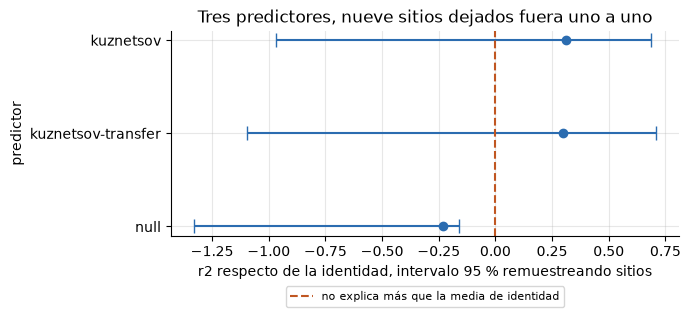

In [8]:
# Los tres puntajes con sus intervalos de remuestreo de sitios, con la línea de cero marcada
names = list(scored)
fig, ax = plt.subplots(figsize=(7, 3.4))
for position, name in enumerate(names):
    point, low, high = scored[name][2:]
    ax.errorbar(point, position, xerr=[[point - low], [high - point]], fmt="o", color="#2b6cb0", capsize=5)
ax.axvline(0, color="#c05621", ls="--", label="no explica más que la media de identidad")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_ylabel("predictor")
ax.set_xlabel("r2 respecto de la identidad, intervalo 95 % remuestreando sitios")
ax.set_title("Tres predictores, nueve sitios dejados fuera uno a uno")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
plt.show()

Cada fila es un predictor: el punto es su varianza explicada respecto de la línea de identidad y el bigote su intervalo de 95 por ciento remuestreando sitios, con la línea punteada en cero. Los dos predictores clásicos tienen casi el mismo punto y casi el mismo bigote, que es el hallazgo principal: el factor propio del sitio no es lo que sostiene el puntaje. Sus bigotes cruzan el cero y alcanzan al del nulo, así que la figura no puede decir que alguno supere a una constante. Tampoco compara directamente los dos predictores clásicos sobre los mismos remuestreos; los intervalos son de cada puntaje, no de su diferencia.

### Paso 4: dónde ayuda y dónde cuesta

Un puntaje agrupado puede ocultar efectos opuestos. La celda puntúa cada uno de los dos predictores clásicos por separado en cada sitio dejado fuera, con el RMSE en metros, y lista el cambio del factor por sitio al predictor de transferencia. Un cambio positivo significa que quitar el factor propio del sitio empeoró las predicciones de ese sitio.

In [9]:
# RMSE del predictor de factor por sitio y del de transferencia en cada sitio dejado fuera
by_site = {}
for name in ("kuznetsov", "kuznetsov-transfer"):
    blasts, preds = scored[name][:2]
    for site in sorted({b.site for b in blasts}):
        pairs = [(b, p) for b, p in zip(blasts, preds) if b.site == site]
        by_site.setdefault(site, {})[name] = bf.score([b for b, _ in pairs], [p for _, p in pairs]).rmse_m
rows = []
for site, v in by_site.items():
    constant, moved = v["kuznetsov"], v["kuznetsov-transfer"]
    rows.append((site, f"{constant:.3f}", f"{moved:.3f}", f"{moved - constant:+.3f}"))
show_table(["sitio dejado fuera", "RMSE kuznetsov (m)", "RMSE kuznetsov-transfer (m)", "cambio (m)"], rows)

| sitio dejado fuera | RMSE kuznetsov (m) | RMSE kuznetsov-transfer (m) | cambio (m) |
|:---|---:|---:|---:|
| Akdaglar | 0.054 | 0.057 | +0.003 |
| Dongri-Buzurg | 0.330 | 0.290 | -0.040 |
| Enusa | 0.147 | 0.175 | +0.028 |
| Mrica | 0.111 | 0.213 | +0.102 |
| Murgul | 0.052 | 0.110 | +0.057 |
| Ozmert | 0.061 | 0.061 | +0.000 |
| Reocin | 0.216 | 0.166 | -0.050 |
| Reocin-UG | 0.093 | 0.086 | -0.007 |
| Soma | 0.132 | 0.076 | -0.056 |

Los efectos son mixtos. El predictor de transferencia es peor en cuatro sitios: Mrica en 0.102 m, Murgul en 0.057 m, Enusa en 0.028 m y Akdaglar en 0.003 m, e igual en Ozmert. Es mejor en cuatro: Soma en 0.056 m, Reocin en 0.050 m, Dongri-Buzurg en 0.040 m y Reocin-UG en 0.007 m. En el sitio del mayor error de factor, Dongri-Buzurg, el factor salió 42.6 por ciento demasiado alto y aun así el RMSE bajó, porque el predictor de factor por sitio ya fallaba en 0.330 m. Así que el resultado agrupado de unas milésimas de metro es un balance de efectos mayores con ambos signos, no una ausencia de efecto.

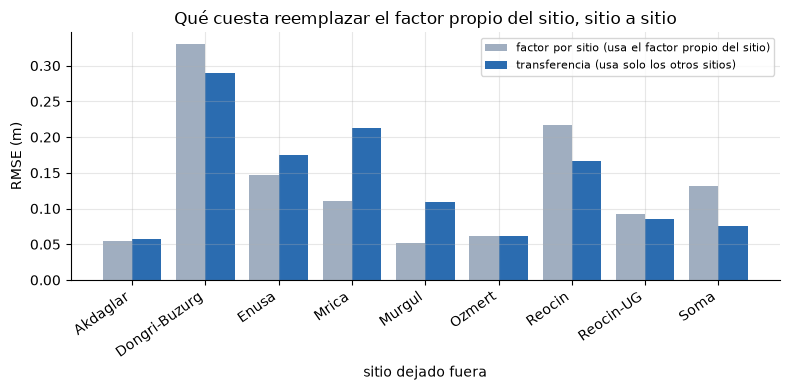

In [10]:
# RMSE por sitio de los dos predictores clásicos, lado a lado
names = list(by_site)
positions = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
constant_label = "factor por sitio (usa el factor propio del sitio)"
transfer_label = "transferencia (usa solo los otros sitios)"
constant = [by_site[s]["kuznetsov"] for s in names]
moved = [by_site[s]["kuznetsov-transfer"] for s in names]
ax.bar(positions - 0.2, constant, width=0.4, color="#a0aec0", label=constant_label)
ax.bar(positions + 0.2, moved, width=0.4, color="#2b6cb0", label=transfer_label)
ax.set_xticks(positions, names, rotation=35, ha="right")
ax.set_xlabel("sitio dejado fuera")
ax.set_ylabel("RMSE (m)")
ax.set_title("Qué cuesta reemplazar el factor propio del sitio, sitio a sitio")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Para cada sitio dejado fuera la barra gris es el RMSE del predictor que usa el factor propio del sitio y la azul el del que usa solo los otros sitios. La azul es más alta en Mrica, Murgul y Enusa, y más baja en Dongri-Buzurg, Reocin y Soma; en Akdaglar y Ozmert las barras son iguales. El tamaño de las barras también varía en un factor de seis entre sitios, así que los grandes errores de Dongri-Buzurg dominan en ambos casos. La figura muestra que el costo de la transferencia es específico de cada sitio; no dice qué sitios serán fáciles en una mina nueva, algo que ninguna figura con nueve sitios puede decir.

## Resultados

**Respuesta:** Sí, con un error de alrededor de un quinto. Predicho solo desde el módulo de los otros nueve sitios, el factor de roca de un sitio dejado fuera tiene un error relativo absoluto mediano de 17.6 por ciento y un error máximo de 42.6 por ciento (Dongri-Buzurg), contra el factor recuperado del artículo. El costo en predicción es pequeño: bajo dejar-un-sitio-fuera el predictor de transferencia explica 0.2982 de la varianza y el de factor por sitio 0.3112, con RMSE de 0.1543 m y 0.1528 m, y ambos intervalos, que remuestrean sitios, abarcan el cero (-1.097 a 0.708 y -0.966 a 0.686). El modelo nulo puntúa -0.2320, con un intervalo de -1.330 a -0.158 que se traslapa con los clásicos. Sitio a sitio el efecto tiene ambos signos, de +0.102 m en Mrica a -0.056 m en Soma.

**Qué se sigue.** El puntaje clásico con campañas dejadas fuera no era principalmente prestado del factor propio del sitio: sobrevive a que ese factor se reemplace por uno predicho desde el módulo. Un lector que compare el predictor clásico con los aprendidos bajo el mismo protocolo puede entonces usar el predictor de transferencia, que no tiene conocimiento del sitio objetivo, como la entrada clásica justa.

**Lo que este notebook no muestra.** Respalda una sola afirmación: el puntaje entre sitios del predictor clásico no depende de la constante del sitio. No dice que la ecuación clásica tenga habilidad en una mina nueva, porque el intervalo abarca el cero y se traslapa con el del nulo. La recta sigue ajustada a factores recuperados de las predicciones publicadas de los otros sitios, y el predictor es una calibración de este motor, no una relación publicada. Los intervalos son de cada puntaje, no de la diferencia entre dos predictores.

## Resumen

- El predictor de transferencia ajusta una recta `ln A = a + b ln E` por nueve sitios (intercepto 0.3841, pendiente 0.5029, correlación 0.891) y no usa nada del sitio sobre el que se puntúa (afirmación BS-4).
- Predicho desde los otros sitios, el factor tiene un error relativo absoluto mediano de 17.6 por ciento y un máximo de 42.6 por ciento.
- Bajo dejar-un-sitio-fuera puntúa 0.2982 contra 0.3112 del factor por sitio, y ambos intervalos, que remuestrean sitios, abarcan el cero.
- Sitio a sitio el cambio en RMSE va de +0.102 m en Mrica a -0.056 m en Soma, así que la pequeña diferencia agrupada es un balance de efectos mayores.
- Siguiente: el tema 03 convierte un tamaño medio en una distribución de tamaños completa.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y el factor que se estimó para cada tiro)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el conjunto de validación de 2012 de cuya columna se recuperan los factores)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestrear la unidad correcta bajo dependencia)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/